In [1]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

In [2]:
class CliffWalkingEnv:
    def __init__(self, rows=4, cols=12):
        self.rows, self.cols = rows, cols
        self.n_states = rows * cols
        self.n_actions = 4                      # 0=Up, 1=Right, 2=Down, 3=Left
        self.start = (rows - 1, 0)
        self.goal = (rows - 1, cols - 1)
        self.cliff = [(rows - 1, c) for c in range(1, cols - 1)]
        self.pos = self.start

    def _to_state(self, pos):
        return pos[0] * self.cols + pos[1]

    def reset(self):
        self.pos = self.start
        return self._to_state(self.pos)

    def step(self, action):
        r, c = self.pos
        if action == 0:   r = max(r - 1, 0)
        elif action == 1: c = min(c + 1, self.cols - 1)
        elif action == 2: r = min(r + 1, self.rows - 1)
        elif action == 3: c = max(c - 1, 0)
        self.pos = (r, c)

        if self.pos in self.cliff:               # fell off the cliff
            self.pos = self.start
            return self._to_state(self.pos), -100, False
        if self.pos == self.goal:                # reached goal
            return self._to_state(self.pos), -1, True
        return self._to_state(self.pos), -1, False

env = CliffWalkingEnv()
print("States:", env.n_states, "| Actions:", env.n_actions)

States: 48 | Actions: 4


In [3]:
def epsilon_greedy(Q, state, epsilon, rng):
    """Random action with prob epsilon, else best action (ties broken randomly)."""
    if rng.random() < epsilon:
        return int(rng.integers(Q.shape[1]))
    best = np.flatnonzero(Q[state] == Q[state].max())
    return int(rng.choice(best))


def q_learning(env, episodes=500, alpha=0.5, gamma=1.0, epsilon=0.1, seed=0, max_steps=500):
    rng = np.random.default_rng(seed)
    Q = np.zeros((env.n_states, env.n_actions))
    rewards = []
    for ep in range(episodes):
        s = env.reset()
        total = 0
        for _ in range(max_steps):
            a = epsilon_greedy(Q, s, epsilon, rng)
            s2, r, done = env.step(a)
            # Q-learning: use the BEST next action (max)
            target = r + gamma * Q[s2].max() * (not done)
            Q[s, a] += alpha * (target - Q[s, a])
            s = s2
            total += r
            if done:
                break
        rewards.append(total)
    return Q, np.array(rewards)


def sarsa(env, episodes=500, alpha=0.5, gamma=1.0, epsilon=0.1, seed=0, max_steps=500):
    rng = np.random.default_rng(seed)
    Q = np.zeros((env.n_states, env.n_actions))
    rewards = []
    for ep in range(episodes):
        s = env.reset()
        a = epsilon_greedy(Q, s, epsilon, rng)
        total = 0
        for _ in range(max_steps):
            s2, r, done = env.step(a)
            a2 = epsilon_greedy(Q, s2, epsilon, rng)
            # SARSA: use the NEXT ACTION ACTUALLY CHOSEN
            target = r + gamma * Q[s2, a2] * (not done)
            Q[s, a] += alpha * (target - Q[s, a])
            s, a = s2, a2
            total += r
            if done:
                break
        rewards.append(total)
    return Q, np.array(rewards)

In [4]:
episodes = 500
Q_ql, rew_ql = q_learning(env, episodes=episodes, seed=1)
Q_sa, rew_sa = sarsa(env, episodes=episodes, seed=1)

print("Last 50 episodes - average reward")
print("  Q-learning:", rew_ql[-50:].mean().round(2))
print("  SARSA     :", rew_sa[-50:].mean().round(2))

Last 50 episodes - average reward
  Q-learning: -27.28
  SARSA     : -25.04


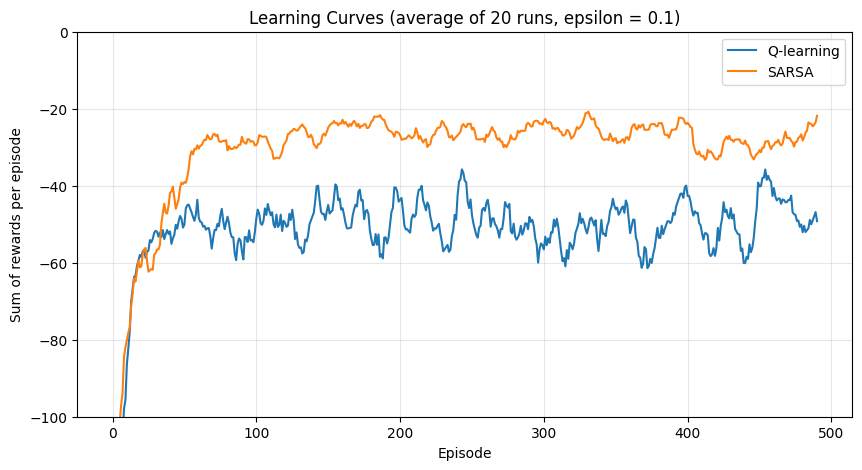

In [5]:
# Average over 20 independent runs to get smooth curves
runs = 20
avg_ql = np.mean([q_learning(env, episodes, seed=s)[1] for s in range(runs)], axis=0)
avg_sa = np.mean([sarsa(env, episodes, seed=s)[1] for s in range(runs)], axis=0)

def smooth(x, k=10):
    return np.convolve(x, np.ones(k) / k, mode="valid")

plt.figure(figsize=(10, 5))
plt.plot(smooth(avg_ql), label="Q-learning")
plt.plot(smooth(avg_sa), label="SARSA")
plt.ylim(-100, 0)
plt.xlabel("Episode")
plt.ylabel("Sum of rewards per episode")
plt.title(f"Learning Curves (average of {runs} runs, epsilon = 0.1)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Why is SARSA's reward higher during training?** Q-learning learns the *optimal* path, which runs right along the cliff edge. But while training, the epsilon-greedy agent sometimes takes a random step and falls off, so its online reward is lower. SARSA takes the exploration into account (on-policy), so it learns a longer but *safer* path away from the cliff.

In [6]:
ARROWS = ["↑", "→", "↓", "←"]

def show_policy(Q, env, title):
    print(title)
    for r in range(env.rows):
        row = ""
        for c in range(env.cols):
            if (r, c) == env.goal:
                row += " G "
            elif (r, c) in env.cliff:
                row += " C "
            else:
                row += " " + ARROWS[int(np.argmax(Q[r * env.cols + c]))] + " "
        print(row)
    print()

def greedy_path(Q, env, max_steps=100):
    s, path = env.reset(), [env.start]
    for _ in range(max_steps):
        s, r, done = env.step(int(np.argmax(Q[s])))
        path.append(env.pos)
        if done:
            break
    return path

show_policy(Q_ql, env, "Q-learning policy (greedy):")
show_policy(Q_sa, env, "SARSA policy (greedy):")

Q-learning policy (greedy):
 →  →  ↑  →  →  →  ↑  →  →  ↑  ↓  ↓ 
 ←  ↓  ↓  →  →  →  →  ↓  →  →  ↓  ↓ 
 →  →  →  →  →  →  →  →  →  →  →  ↓ 
 ↑  C  C  C  C  C  C  C  C  C  C  G 

SARSA policy (greedy):
 →  →  →  →  →  →  →  →  →  →  ↓  ↓ 
 ↑  ↑  ↑  →  →  ↑  →  ↑  ↑  →  →  ↓ 
 ↑  ↑  →  ↑  →  ↑  →  ↑  ↑  →  →  ↓ 
 ↑  C  C  C  C  C  C  C  C  C  C  G 



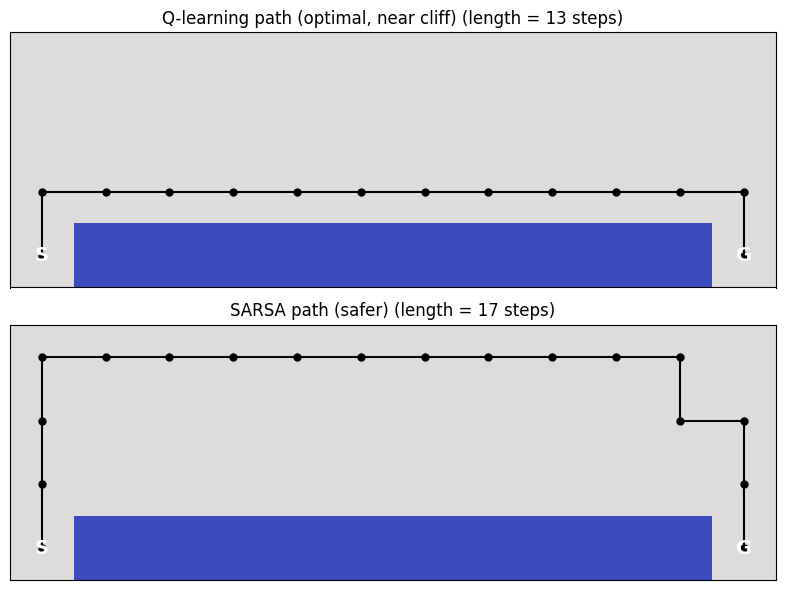

In [7]:
# Plot the greedy paths on the grid
def plot_path(ax, path, title):
    grid = np.zeros((env.rows, env.cols))
    for (r, c) in env.cliff:
        grid[r, c] = -1
    ax.imshow(grid, cmap="coolwarm", vmin=-1, vmax=1)
    ys, xs = zip(*path)
    ax.plot(xs, ys, "k-o", markersize=5)
    ax.text(env.start[1], env.start[0], "S", color="white", ha="center", va="center", fontsize=14, weight="bold")
    ax.text(env.goal[1], env.goal[0], "G", color="white", ha="center", va="center", fontsize=14, weight="bold")
    ax.set_title(f"{title} (length = {len(path) - 1} steps)")
    ax.set_xticks([]); ax.set_yticks([])

fig, axes = plt.subplots(2, 1, figsize=(10, 6))
plot_path(axes[0], greedy_path(Q_ql, env), "Q-learning path (optimal, near cliff)")
plot_path(axes[1], greedy_path(Q_sa, env), "SARSA path (safer)")
plt.tight_layout()
plt.show()

In [ ]:
# Effect of learning rate alpha (Q-learning)
plt.figure(figsize=(10, 5))
for alpha in [0.1, 0.3, 0.5, 0.9]:
    avg = np.mean([q_learning(env, 300, alpha=alpha, seed=s)[1] for s in range(10)], axis=0)
    plt.plot(smooth(avg), label=f"alpha = {alpha}")
plt.ylim(-100, 0)
plt.xlabel("Episode"); plt.ylabel("Sum of rewards")
plt.title("Effect of Learning Rate (Q-learning)")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [ ]:
# Effect of exploration rate epsilon (Q-learning)
plt.figure(figsize=(10, 5))
for eps in [0.01, 0.1, 0.3]:
    avg = np.mean([q_learning(env, 300, epsilon=eps, seed=s)[1] for s in range(10)], axis=0)
    plt.plot(smooth(avg), label=f"epsilon = {eps}")
plt.ylim(-100, 0)
plt.xlabel("Episode"); plt.ylabel("Sum of rewards")
plt.title("Effect of Exploration Rate (Q-learning)")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

- **Higher alpha** learns faster but can be unstable; **lower alpha** is smoother but slower.
- **Higher epsilon** explores more (more random falls, lower online reward); **epsilon too low** may never discover better paths.

## Part 6: Python Packages for Reinforcement Learning
Writing everything from scratch (as above) is good for learning. In practice, people use libraries:

| Package | Purpose | Key points |
|---|---|---|
| **Gymnasium** (successor of OpenAI Gym) | Standard **environments** and API | `make`, `reset`, `step`; ships CartPole, FrozenLake, MountainCar, Atari, MuJoCo, ... |
| **Stable-Baselines3 (SB3)** | Ready-made **algorithms** (PyTorch) | PPO, A2C, DQN, SAC, TD3; train with `model.learn()` |
| **Ray RLlib** | Scalable / distributed RL | Many algorithms, multi-agent, runs on clusters |
| **TF-Agents** | RL in TensorFlow | Modular agents, policies, replay buffers |
| **Tianshou** | Fast modular RL (PyTorch) | Many algorithms with a clean API |
| **CleanRL** | Simple single-file implementations | Great for reading and understanding algorithms |
| **PettingZoo** | Multi-agent environments | Gymnasium-style API for several agents |

**Typical workflow:** Gymnasium provides the *environment*, and SB3 (or another library) provides the *algorithm*.

- RL learns from **rewards through interaction**, not from labelled data.
- **Q-learning** (off-policy) learns the optimal path, using the max over next actions. **SARSA** (on-policy) learns using the action it actually takes, so it prefers a safer path while exploring.
- On Cliff Walking, Q-learning finds the shortest path near the cliff but earns lower reward *during training*; SARSA finds a longer safe path and earns higher online reward.
- **Hyperparameters** matter: alpha controls learning speed and stability, epsilon controls exploration, gamma controls how much the future matters.
- **Gymnasium** provides standard environments with the `reset` / `step` API, and libraries like **Stable-Baselines3** provide ready-made algorithms (PPO, DQN, A2C, ...) so you do not code everything by hand.
- Tabular methods (Q-table) work for small discrete problems; for large or continuous problems we need **deep RL** (DQN, PPO), which SB3 provides.
